# Predição de manutenção industrial

Notebook enxuto para analisar os sensores, comparar modelos e salvar o melhor classificador de `maintenance_required`. A divisão é temporal: os primeiros 70% treinam e os últimos 30% simulam dados posteriores. `timestamp` e `machine_id` são removidos antes da modelagem.


## 1. Configuração e dados

A vibração negativa é inválida e vira `NaN`; o imputador trata esse valor dentro de cada pipeline. A ordenação temporal é feita antes da remoção de `timestamp`.


In [18]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEMENTE = 42
FEATURES = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]
ALVO = "maintenance_required"
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

dados = pd.read_csv(raiz / "data" / "smart_manufacturing_data.csv")
dados["timestamp"] = pd.to_datetime(dados["timestamp"], errors="coerce")
dados = dados.sort_values("timestamp").reset_index(drop=True)
datas = dados["timestamp"].copy()
negativas = int((dados["vibration"] < 0).sum())
dados.loc[dados["vibration"] < 0, "vibration"] = np.nan
duplicatas = int(dados.duplicated().sum())
dados = dados.drop(columns=["timestamp", "machine_id"])
print(f"Dimensões: {dados.shape} | Vibrações inválidas: {negativas} | Duplicatas: {duplicatas}")


Dimensões: (100000, 11) | Vibrações inválidas: 37 | Duplicatas: 0


## 2. EDA rápida

A classe positiva é minoritária. Os limites da regra tradicional são mostrados nos histogramas para contextualizar os modelos.


,count,mean,std,min,25%,50%,75%,max
temperature,100000.0,75.015625,10.031884,35.55,68.2675,75.06,81.750,121.94
vibration,99963.0,50.032540,14.950896,0.10,39.9850,49.97,60.105,113.80
humidity,100000.0,54.995401,14.437960,30.00,42.5200,54.98,67.500,80.00
pressure,100000.0,3.000405,1.152399,1.00,2.0000,3.01,4.000,5.00
energy_consumption,100000.0,2.747064,1.297865,0.50,1.6300,2.74,3.870,5.00
maintenance_required,100000.0,0.196970,0.397711,0.00,0.0000,0.00,0.000,1.00


Nulos restantes: 37
Taxa de manutenção: 19.7%


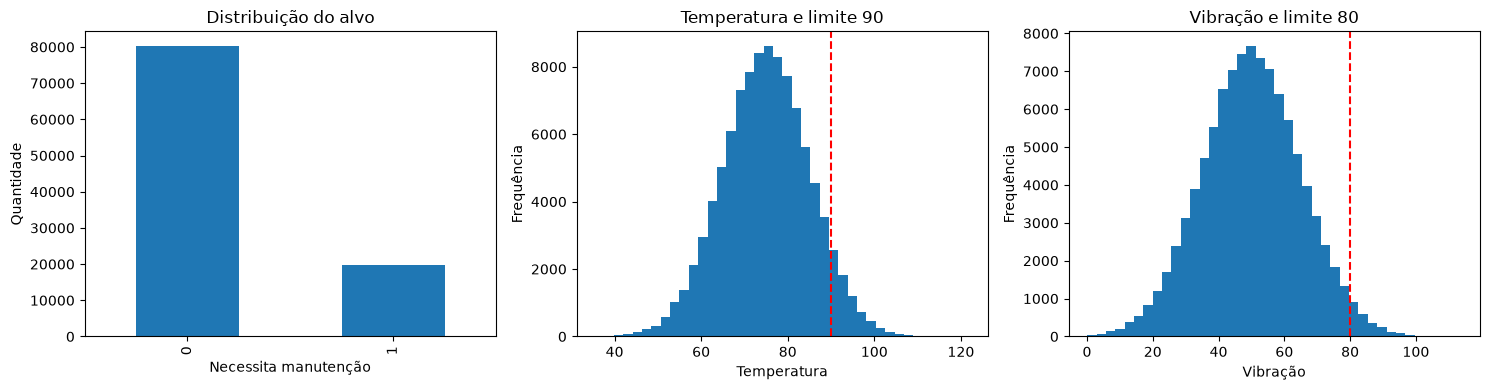

In [19]:
display(dados[FEATURES + [ALVO]].describe().T)
print(f"Nulos restantes: {int(dados.isna().sum().sum())}")
print(f"Taxa de manutenção: {dados[ALVO].mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
dados[ALVO].value_counts().sort_index().plot.bar(ax=axes[0], title="Distribuição do alvo")
axes[0].set_xlabel("Necessita manutenção"); axes[0].set_ylabel("Quantidade")
axes[1].hist(dados.temperature, bins=40); axes[1].axvline(90, color="red", linestyle="--")
axes[1].set(title="Temperatura e limite 90", xlabel="Temperatura", ylabel="Frequência")
axes[2].hist(dados.vibration.dropna(), bins=40); axes[2].axvline(80, color="red", linestyle="--")
axes[2].set(title="Vibração e limite 80", xlabel="Vibração", ylabel="Frequência")
plt.tight_layout(); plt.show()


## 3. Divisão temporal e baseline

A regra de alerta é `temperature > 90` ou `vibration > 80`. Ela serve como referência antes dos modelos.


In [20]:
corte = int(len(dados) * .70)
treino, teste = dados.iloc[:corte], dados.iloc[corte:]
X_treino, X_teste = treino[FEATURES], teste[FEATURES]
y_treino, y_teste = treino[ALVO].astype(int), teste[ALVO].astype(int)
print(f"Treino: {len(treino):,} ({datas.iloc[0]} até {datas.iloc[corte - 1]})")
print(f"Teste: {len(teste):,} ({datas.iloc[corte]} até {datas.iloc[-1]})")

alerta = ((X_teste.temperature > 90) | (X_teste.vibration > 80)).astype(int)
metricas = lambda real, pred, prob: {
    "accuracy": accuracy_score(real, pred),
    "precision": precision_score(real, pred, zero_division=0),
    "recall": recall_score(real, pred, zero_division=0),
    "f1": f1_score(real, pred, zero_division=0),
    "roc_auc": roc_auc_score(real, prob),
    "pr_auc": average_precision_score(real, prob),
}
regra = metricas(y_teste, alerta, alerta.astype(float))
print("Regra de alerta:", {k: round(v, 3) for k, v in regra.items()})


Treino: 70,000 (2025-01-01 00:00:00 até 2025-02-18 14:39:00)
Teste: 30,000 (2025-02-18 14:40:00 até 2025-03-11 10:39:00)
Regra de alerta: {'accuracy': 0.892, 'precision': 1.0, 'recall': 0.457, 'f1': 0.627, 'roc_auc': 0.728, 'pr_auc': 0.564}


## 4. Modelos candidatos

A imputação e a padronização ficam dentro do pipeline. A seleção usa apenas validação temporal do treino, com PR-AUC.


In [21]:
def pipeline(modelo, escala=False):
    etapas = [("imputador", SimpleImputer(strategy="median"))]
    if escala: etapas.append(("escala", StandardScaler()))
    etapas.append(("modelo", modelo))
    return Pipeline(etapas)

modelos = {
    "Regressão logística": pipeline(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEMENTE), True),
    "Árvore": pipeline(DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=SEMENTE)),
    "Random Forest": pipeline(RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=SEMENTE, n_jobs=-1)),
    "HistGradientBoosting": pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=SEMENTE)),
}
cv = TimeSeriesSplit(n_splits=5)
cv_resultados = []
for nome, modelo in modelos.items():
    scores = []
    for i, j in cv.split(X_treino):
        ajuste = clone(modelo).fit(X_treino.iloc[i], y_treino.iloc[i])
        scores.append(average_precision_score(y_treino.iloc[j], ajuste.predict_proba(X_treino.iloc[j])[:, 1]))
    cv_resultados.append({"modelo": nome, "pr_auc_cv": np.mean(scores)})
cv_df = pd.DataFrame(cv_resultados).sort_values("pr_auc_cv", ascending=False)
modelo_escolhido = cv_df.iloc[0].modelo
print(f"Modelo escolhido no treino: {modelo_escolhido}")
display(cv_df.style.format({"pr_auc_cv": "{:.3f}"}))


Modelo escolhido no treino: Random Forest


,modelo,pr_auc_cv
2,Random Forest,0.631
3,HistGradientBoosting,0.630
1,Árvore,0.558
0,Regressão logística,0.516


## 5. Avaliação no teste

Os modelos são ajustados no treino completo e avaliados no mesmo teste. A escolha já foi feita sem consultar o teste.


,accuracy,precision,recall,f1,roc_auc,pr_auc
modelo,,,,,,
HistGradientBoosting,0.888,0.944,0.460,0.619,0.726,0.636
Random Forest,0.892,0.997,0.458,0.627,0.725,0.635
Árvore,0.892,1.000,0.457,0.627,0.728,0.564
Regra de alerta,0.892,1.000,0.457,0.627,0.728,0.564
Regressão logística,0.643,0.307,0.638,0.415,0.703,0.526


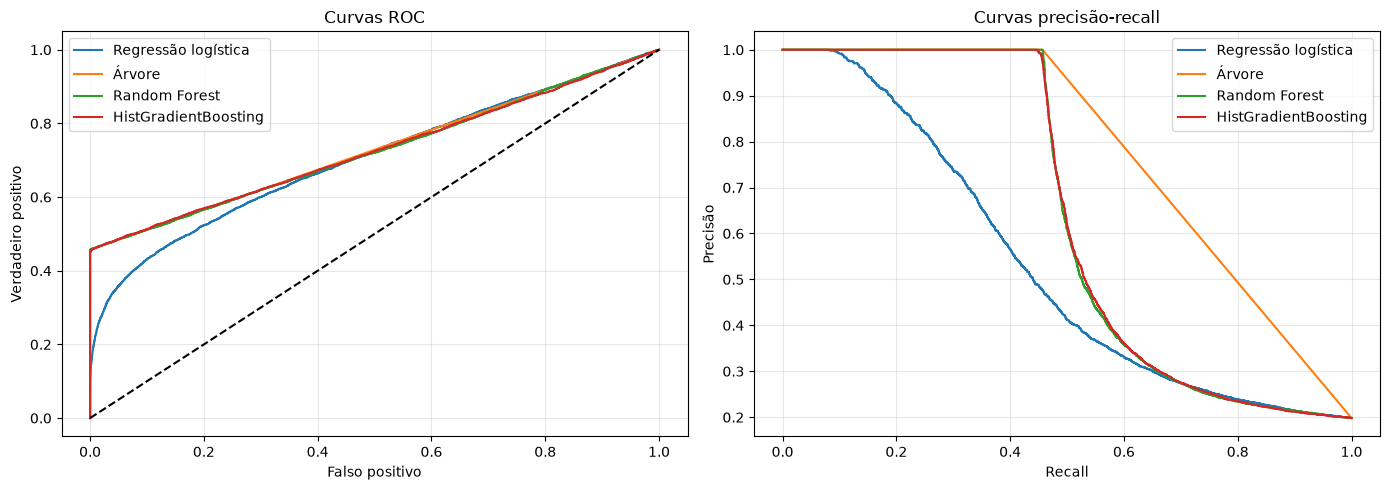

In [22]:
ajustados, probabilidades, tabela = {}, {}, []
for nome, modelo in modelos.items():
    ajuste = clone(modelo).fit(X_treino, y_treino)
    prob = ajuste.predict_proba(X_teste)[:, 1]
    pred = (prob >= .5).astype(int)
    ajustados[nome], probabilidades[nome] = ajuste, prob
    tabela.append({"modelo": nome, **metricas(y_teste, pred, prob)})
tabela.append({"modelo": "Regra de alerta", **regra})
comparacao = pd.DataFrame(tabela).set_index("modelo").sort_values("pr_auc", ascending=False)
display(comparacao.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nome, prob in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_teste, prob)
    precisao, recall, _ = precision_recall_curve(y_teste, prob)
    axes[0].plot(fpr, tpr, label=nome)
    axes[1].plot(recall, precisao, label=nome)
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(title="Curvas ROC", xlabel="Falso positivo", ylabel="Verdadeiro positivo")
axes[1].set(title="Curvas precisão-recall", xlabel="Recall", ylabel="Precisão")
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()


## 6. Modelo final e importância

A matriz de confusão e a importância por permutação ajudam a interpretar o modelo escolhido. Importância não significa causalidade.


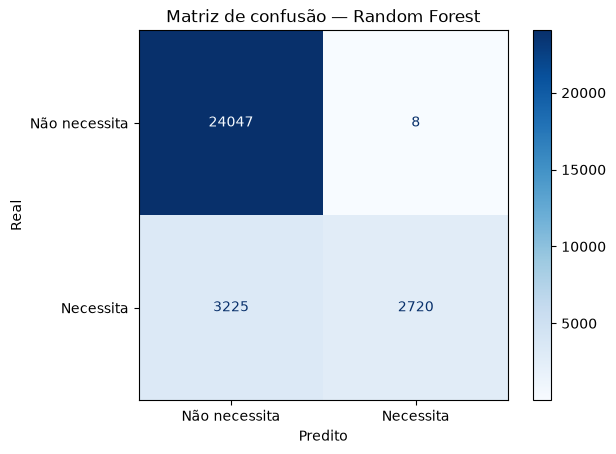

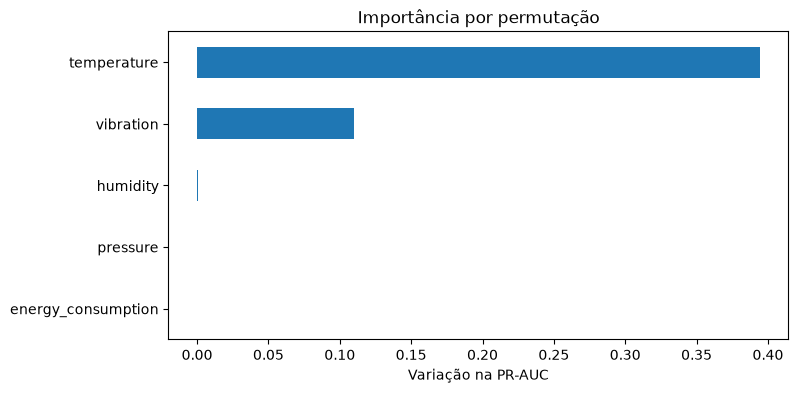

Recall do modelo: 0.458 | Recall da regra: 0.457


In [23]:
modelo_final = ajustados[modelo_escolhido]
prob_final = probabilidades[modelo_escolhido]
pred_final = (prob_final >= .5).astype(int)
ConfusionMatrixDisplay.from_predictions(y_teste, pred_final, display_labels=["Não necessita", "Necessita"], cmap="Blues")
plt.title(f"Matriz de confusão — {modelo_escolhido}"); plt.xlabel("Predito"); plt.ylabel("Real"); plt.show()

permutacao = permutation_importance(modelo_final, X_teste, y_teste, scoring="average_precision", n_repeats=5, random_state=SEMENTE, n_jobs=-1)
pd.Series(permutacao.importances_mean, index=FEATURES).sort_values().plot.barh(title="Importância por permutação", figsize=(8, 4))
plt.xlabel("Variação na PR-AUC"); plt.show()
print(f"Recall do modelo: {comparacao.loc[modelo_escolhido, 'recall']:.3f} | Recall da regra: {regra['recall']:.3f}")


## 7. Salvamento

O pipeline completo é salvo para ser carregado por uma API.


In [24]:
pasta = raiz / "ml-model" / "models"
pasta.mkdir(exist_ok=True)
artefato = {
    "pipeline": modelo_final,
    "features": FEATURES,
    "limiar": 0.5,
    "data_corte_treino": str(datas.iloc[corte - 1]),
    "metricas_teste": {k: float(v) for k, v in comparacao.loc[modelo_escolhido].to_dict().items()},
}
modelo_path = pasta / "modelo_manutencao.joblib"
joblib.dump(artefato, modelo_path)
carregado = joblib.load(modelo_path)
print(f"Modelo salvo em: {modelo_path}")
display(pd.DataFrame({"predicao": carregado["pipeline"].predict(X_teste.head(3)), "probabilidade": carregado["pipeline"].predict_proba(X_teste.head(3))[:, 1]}))


Modelo salvo em: /Users/sandrobcs/Folders/smart talent/smart-talent-oee/ml-model/models/modelo_manutencao.joblib


,predicao,probabilidade
0,0,0.363625
1,0,0.282463
2,0,0.343361
